In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from STWaveGraph.STWaveGraph import STWaveGraph
import matplotlib.pyplot as plt

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
import rpy2

In [ ]:
dataset = '151673'
n_clusters = 5 if dataset in ['151669', '151670', '151671', '151672'] else 7
file_fold = '/root/workspace/STWaveGraph-main/Data/DLPFC/' + str(dataset) #please replace 'file_fold' with the download path
adata = sc.read_visium(file_fold, count_file='filtered_feature_bc_matrix.h5', load_images=True)
adata.var_names_make_unique()

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
import torch
print("PyTorch版本:", torch.__version__)
print("CUDA是否可用:", torch.cuda.is_available())

PyTorch版本: 2.4.1+cu124
CUDA是否可用: True


73:600:3500:random seed: 6497
6382:0.671
76:seed: 5549:0.603
510:seed: 8951:0.516

In [5]:
model = STWaveGraph(
    adata=adata,
    n_clusters=n_clusters,
    device=device,

    n_top_genes=2500,
    pca_dim=40,
    n_neighbors_spatial=6,
    expr_power=1.4,

    pretrain_epochs=250,
    finetune_epochs=200,

    lambda_rec=0.3,
    lambda_ssl=0.5,
    lambda_smooth=0.015,
    lambda_kl=1.2,
    lambda_q_cons=0.3,      
    lambda_balance=0.0,
    lambda_boundary=0.25,

    refine_iters=1
)
adata = model.train(verbose=True)

========== Stage 1: Representation Pretraining ==========


100%|██████████| 250/250 [00:24<00:00, 10.23it/s]


========== Initialize Cluster Centers ==========
========== Stage 2: Clustering Finetuning ==========


 26%|██▌       | 51/200 [00:04<00:12, 11.62it/s]

[Finetune] Epoch 50/200 | loss=0.8324 | rec=1.8582 | ssl=0.2922 | smooth=0.3750 | kl=0.0592 | balance=0.0010 | bd=0.2071 | extra_reg_on=1


...

[Finetune] Epoch 100/200 | loss=0.7731 | rec=1.7299 | ssl=0.2343 | smooth=0.3815 | kl=0.0666 | balance=0.0012 | bd=0.2043 | extra_reg_on=1


 76%|███████▌  | 151/200 [00:12<00:04, 11.63it/s]

[Finetune] Epoch 150/200 | loss=0.7231 | rec=1.6149 | ssl=0.1894 | smooth=0.3770 | kl=0.0720 | balance=0.0014 | bd=0.2060 | extra_reg_on=1


100%|██████████| 200/200 [00:17<00:00, 11.64it/s]


[Finetune] Epoch 200/200 | loss=0.6819 | rec=1.5142 | ssl=0.1607 | smooth=0.3715 | kl=0.0744 | balance=0.0015 | bd=0.2084 | extra_reg_on=1
fitting ...
  |======================================================================| 100%


In [6]:
# add ground_truth
df_meta = pd.read_csv(file_fold + '/metadata.tsv', sep='\t')
df_meta_layer = df_meta['layer_guess']
adata.obs['ground_truth'] = df_meta_layer.values

In [7]:
adata

AnnData object with n_obs × n_vars = 3639 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'pred_domain_raw', 'pred_domain', 'ground_truth'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'spatial', 'hvg', 'log1p', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [8]:
adata.obsm['emb']

array([[-0.02665446,  0.08908682,  0.11052157, ...,  0.11996543,
         0.02181573,  0.06645859],
       [ 0.01740771,  0.12376314, -0.07427789, ...,  0.11333929,
         0.23466119, -0.00674031],
       [-0.11493684,  0.03582689, -0.08765535, ..., -0.110506  ,
        -0.13548613,  0.11241489],
       ...,
       [-0.01635331, -0.03976752, -0.05929167, ...,  0.10699532,
        -0.0218592 , -0.04121297],
       [-0.09104975, -0.09637413, -0.03463962, ...,  0.03310327,
        -0.05465006, -0.03805729],
       [-0.10178914,  0.05108884,  0.09482054, ...,  0.09521034,
         0.03429963,  0.05097791]], dtype=float32)

In [9]:
# filter out NA nodes
adata = adata[~pd.isnull(adata.obs['ground_truth'])]

# calculate metric ARI
ARI = metrics.adjusted_rand_score(adata.obs['pred_domain'], adata.obs['ground_truth'])
adata.uns['ARI'] = ARI

print('Dataset:', dataset)
print('ARI:', ARI)

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


Dataset: 151673
ARI: 0.6569714058311509


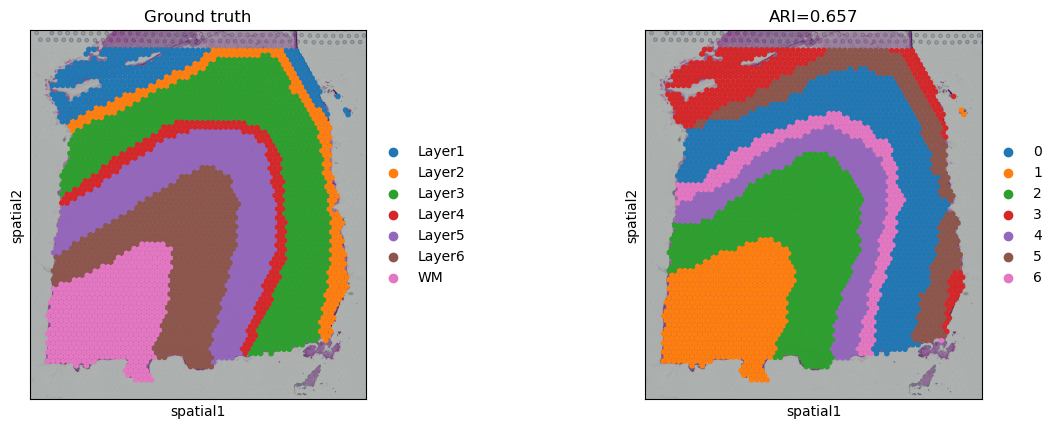

In [10]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["ground_truth", "pred_domain"],
    title=["Ground truth", f"ARI={ARI:.3f}"],
    spot_size=150,
    show=True
)


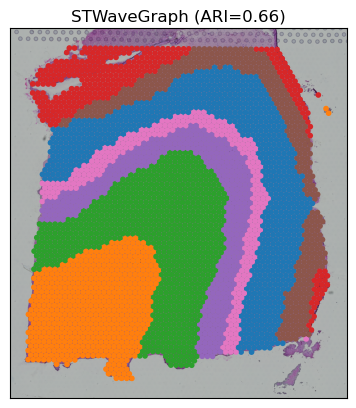

In [11]:

import matplotlib.pyplot as plt
# plotting spatial clustering result 
sc.pl.spatial(adata, 
              img_key="hires", 
              color=["pred_domain"],
              title=["STWaveGraph (ARI=%.5f)"%ARI],
              legend_loc=None,
              spot_size=150,
              show=False,)  

# 获取当前图形和坐标轴
fig = plt.gcf()
ax = plt.gca()

# 去掉 x 和 y 轴的标签
ax.set_xlabel('')
ax.set_ylabel('')

# 添加新的标题
plt.title("STWaveGraph (ARI=%.2f)"%ARI, pad=5)  # pad 用于调整标题与图形的距离

# 显示图形
plt.show()

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


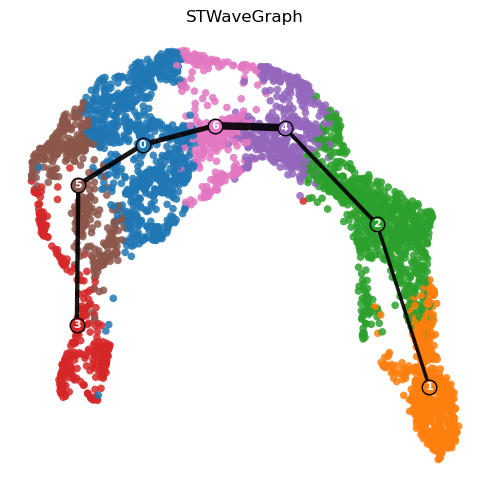

In [12]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp

# ===== 1. 先准备 =====
adata.obs["pred_domain"] = adata.obs["pred_domain"].astype("category")

# 把 X_stwave 改成你的模型 embedding 名字
sc.pp.neighbors(adata, use_rep="emb", n_neighbors=12)
sc.tl.umap(adata, min_dist=0.3)
sc.tl.paga(adata, groups="pred_domain")

# ===== 2. 自定义绘图 =====
coords = adata.obsm["X_umap"]
groups = adata.obs["pred_domain"].astype("category")
cats = list(groups.cat.categories)

if "pred_domain_colors" in adata.uns:
    palette = adata.uns["pred_domain_colors"]
else:
    palette = plt.cm.tab10(np.linspace(0, 1, len(cats)))

color_map = {cat: palette[i] for i, cat in enumerate(cats)}
point_colors = groups.map(color_map)

centers = []
for cat in cats:
    mask = (groups == cat).values
    centers.append(coords[mask].mean(axis=0))
centers = np.vstack(centers)

conn = adata.uns["paga"]["connectivities"]
if sp.issparse(conn):
    conn = conn.toarray()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(coords[:, 0], coords[:, 1], c=point_colors, s=30, alpha=0.85, linewidths=0)

threshold = 0.05
for i in range(len(cats)):
    for j in range(i + 1, len(cats)):
        if conn[i, j] >= threshold:
            ax.plot(
                [centers[i, 0], centers[j, 0]],
                [centers[i, 1], centers[j, 1]],
                color="black",
                lw=1 + 6 * conn[i, j],
                alpha=0.9,
                zorder=5
            )

for i, cat in enumerate(cats):
    ax.scatter(centers[i, 0], centers[i, 1], s=110, color=color_map[cat],
               edgecolor="black", linewidth=1.0, zorder=6)
    ax.text(centers[i, 0], centers[i, 1], str(cat),
            ha="center", va="center", fontsize=8,
            color="white", weight="bold", zorder=7)

ax.set_title("STWaveGraph")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()